# Physical AI 初級実験：距離センサーと自動回避

**今回の目的**：A → B → C → GOALの4地点を巡回しながら、経路上にある未知位置の障害物を検知し、手動で迂回点を指定せず通過する。

2つの条件を比較します。
- **実験1 `baseline`**：既存の決定木AIで目標を追う。障害物を認識しない。
- **実験2 `sensor`**：仮想距離センサーで障害物を観測し、その時点の距離情報から一時的な迂回地点を自動で作る。決定木AIがその目標に向かう行動を選ぶ。

**正確な役割の区別**：決定木AIは前進／左右旋回／停止を選択する。障害物の検知と迂回地点の自動生成は、センサーと幾何学的なルールに基づく。


## 1. ライブラリ

In [1]:
# 必要なものが見つからないときだけ、次の行の # を外して実行
# %pip -q install numpy scikit-learn pillow opencv-python
import math
import csv
import shutil
import subprocess
from pathlib import Path
from dataclasses import dataclass
import numpy as np
import cv2
from PIL import Image, ImageDraw, ImageFont
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
print("準備OK")

準備OK


## 2. 実験条件

In [2]:
ROUTE = [(2.0, 1.10), (4.2, 1.10), (4.2, 3.30), (6.0, 3.30)]
START = (0.65, 0.75, 0.0)
FPS = 12
MAX_TIME = 105
ARRIVAL = 0.23
OBSTACLE_RADIUS = 0.34
ROBOT_RADIUS = 0.14
SCAN_RANGE = 2.0
WHEEL_BASE = 0.32
WHEEL_RADIUS = 0.06
ACTIONS = {-1: 'RIGHT', 0: 'STOP', 1: 'LEFT', 2: 'FORWARD'}

OBSTACLE = (3.10, 1.10, 0.34)  # 実験世界でのみ使う (x, y, 半径)
VIDEO_SECONDS = 80
assert 60 <= VIDEO_SECONDS <= 180

## 3. 目標追従用のAI（既存の決定木）

角度差と目標までの距離から、どの行動を取るか予測します。

In [3]:
def wrap(x): return (x+math.pi)%(2*math.pi)-math.pi

def train_ai():
    rng=np.random.default_rng(42)
    X=np.column_stack([rng.uniform(-math.pi,math.pi,24000),rng.uniform(0,5,24000)])
    a,d=X.T
    y=np.where(d<ARRIVAL,0,np.where(a>.15,1,np.where(a<-.15,-1,2)))
    tr,te,yr,yt=train_test_split(X,y,test_size=.25,random_state=42,stratify=y)
    clf=DecisionTreeClassifier(max_depth=5,random_state=42).fit(tr,yr)
    return clf,clf.score(te,yt)

ai, score = train_ai()
print(f"人工的な教師ラベルへの一致率：{score:.3f}")

人工的な教師ラベルへの一致率：1.000


## 4. 仮想距離センサーと衝突判定

シミュレータだけが障害物の正確な座標を知っています。`lidar` は光線が障害物の表面に当たるまでの距離を返します。ロボット側の判断は**測定した距離**を使います。円形の障害物を想定した簡易モデルです。

In [4]:
@dataclass
class World:
    # 正解の障害物位置。センサー内部と衝突判定以外から呼び出さない。
    obstacle: tuple[float,float,float] | None = (3.10,1.10,OBSTACLE_RADIUS)

    def lidar(self,x,y,bearing):
        """方位bearingの光線が円の表面に最初に当たる距離（範囲外はSCAN_RANGE）"""
        if self.obstacle is None: return SCAN_RANGE
        ox,oy,r=self.obstacle
        ux,uy=math.cos(bearing),math.sin(bearing)
        qx,qy=x-ox,y-oy
        b=qx*ux+qy*uy
        c=qx*qx+qy*qy-r*r
        delta=b*b-c
        if delta<0: return SCAN_RANGE
        root=math.sqrt(delta)
        intersections=(-b-root,-b+root)
        positive=[t for t in intersections if t>=0]
        return min(SCAN_RANGE,min(positive)) if positive else SCAN_RANGE

    def clearance(self,x,y):
        if self.obstacle is None: return float('inf')
        ox,oy,r=self.obstacle
        return math.hypot(x-ox,y-oy)-r-ROBOT_RADIUS

## 5. AIの行動を車輪の動きに変換

前進・左旋回・右旋回・停止を、差動二輪ロボットの速度に変換します。

In [5]:
def action_for_target(ai,x,y,theta,target):
    tx,ty=target
    dist=math.hypot(tx-x,ty-y)
    error=wrap(math.atan2(ty-y,tx-x)-theta)
    return int(ai.predict([[error,dist]])[0]),dist,error

def move(x,y,theta,action,dt):
    if action==1: v,w=.03,.90
    elif action==-1: v,w=.03,-.90
    elif action==2: v,w=.15,0.
    else: v,w=0.,0.
    left=(v-w*WHEEL_BASE/2)/WHEEL_RADIUS
    right=(v+w*WHEEL_BASE/2)/WHEEL_RADIUS
    actual_v=(left+right)*WHEEL_RADIUS/2
    actual_w=(right-left)*WHEEL_RADIUS/WHEEL_BASE
    nx=x+actual_v*math.cos(theta)*dt
    ny=y+actual_v*math.sin(theta)*dt
    nt=wrap(theta+actual_w*dt)
    return nx,ny,nt,left,right

## 6. 走行制御：障害物を発見したら一時的な目標を自動計算

走行中に進行方向の障害物を距離センサーで発見したら、**そのセンサー値から障害物の位置を概算**して一時的な迂回地点を生成します。障害物の事前座標や人間が決めた迂回点は利用しません。

ただし、障害物が半径0.34m程度の円であると想定しており、複雑な障害物には対応できない可能性があります。

In [6]:
def estimated_detour(x,y,goal_bearing,sensor_hit,world,side):
    """距離センサー値から障害物中心を概算し、一時的な迂回点をその場で作る。
    使用するのは sensor_hit と事前に仮定した障害物の半径だけ。
    world.obstacle の座標は参照しない。
    """
    # 円形障害物がレーザー進行方向のほぼ正面にあるという近似
    ux,uy=math.cos(goal_bearing),math.sin(goal_bearing)
    cx=x+(sensor_hit+OBSTACLE_RADIUS)*ux
    cy=y+(sensor_hit+OBSTACLE_RADIUS)*uy
    px,py=-uy*side,ux*side
    margin=OBSTACLE_RADIUS+ROBOT_RADIUS+0.28
    return [
        (cx-ux*(margin+0.13)+px*margin,cy-uy*(margin+0.13)+py*margin),
        (cx+ux*(margin+0.13)+px*margin,cy+uy*(margin+0.13)+py*margin),
    ]

def simulate(mode='sensor',obstacle=(3.1,1.1,OBSTACLE_RADIUS), route=None, max_seconds=MAX_TIME):
    """mode='baseline' は距離情報を使わず元のAIのみ; 'sensor' はセンサーで局所迂回点を生成。"""
    assert mode in ('baseline','sensor')
    route=ROUTE if route is None else route
    world=World(obstacle)
    ai,score=train_ai()
    x,y,theta=START
    idx=0
    subgoals=[]
    phase='GOAL'
    t_finish=None
    detour_count=0
    collisions_prevented=0
    min_clearance=9e9
    rows=[]
    blocked_frames=0
    for frame in range(round(FPS*max_seconds)):
        t=frame/FPS
        done=idx>=len(route)
        goal=route[min(idx,len(route)-1)]
        target=subgoals[0] if subgoals else goal
        sensors={
            'left_m':world.lidar(x,y,theta+math.pi/3),
            'front_m':world.lidar(x,y,theta),
            'right_m':world.lidar(x,y,theta-math.pi/3),
        }
        bearing=math.atan2(goal[1]-y,goal[0]-x)
        target_range=world.lidar(x,y,bearing)
        subgoal_dist=math.hypot(target[0]-x,target[1]-y)
        subgoal_angle=wrap(math.atan2(target[1]-y,target[0]-x)-theta)
        status='COMPLETE' if done else 'RUNNING'
        action=0
        gl_dist=math.hypot(goal[0]-x,goal[1]-y)
        gl_err=wrap(bearing-theta)
        if not done:
            # リアルタイム距離センサーの値で障害物を発見する。障害物の座標は未使用。
            if mode=='sensor' and not subgoals and target_range < min(1.12,gl_dist-.06):
                left_free=world.lidar(x,y,bearing+math.pi/2)
                right_free=world.lidar(x,y,bearing-math.pi/2)
                side=1 if left_free>=right_free else -1
                subgoals=estimated_detour(x,y,bearing,target_range,world,side)
                phase='DETOUR'
                detour_count+=1
                target=subgoals[0]
            action,sub_dist,_=action_for_target(ai,x,y,theta,target)
            subgoal_dist = sub_dist
            subgoal_angle = wrap(math.atan2(target[1]-y,target[0]-x)-theta)
            if sub_dist<ARRIVAL or action==0:
                if subgoals:
                    subgoals.pop(0)
                    phase='DETOUR' if subgoals else 'GOAL'
                else:
                    idx+=1
                    if idx==len(route):
                        t_finish=t
                        status='COMPLETE'
                action=0
            else:
                nx,ny,nt,_,_=move(x,y,theta,action,1/FPS)
                if world.clearance(nx,ny)<=0:
                    action=0
                    collisions_prevented+=1
                    blocked_frames+=1
                    status='BLOCKED'
                else:
                    x,y,theta=nx,ny,nt
        min_clearance=min(min_clearance,world.clearance(x,y))
        rows.append(dict(
            frame=frame,time_s=round(t,3),x_m=round(x,4),y_m=round(y,4),theta_rad=round(theta,4),
            target= 'GOAL' if done else ('via' if subgoals else f'{idx+1}/{len(route)}'),
            phase=phase,checkpoints_reached=idx,action=ACTIONS[action], action_code=action,
            goal_distance_m=round(gl_dist,3), goal_angle_rad=round(gl_err,3),
            steering_target_distance_m=round(subgoal_dist,3),
            steering_target_angle_rad=round(subgoal_angle,3),
            left_sensor_m=round(sensors['left_m'],3), front_sensor_m=round(sensors['front_m'],3),
            right_sensor_m=round(sensors['right_m'],3),goal_ray_m=round(target_range,3),
            clearance_m=round(world.clearance(x,y),3) if world.obstacle else None,
            status=status, collision_blocked=int(status=='BLOCKED'),
            detour_count=detour_count,
        ))
    return rows,dict(mode=mode,reached=rows[-1]['checkpoints_reached'],total=len(route),
                     completion_time=t_finish,prevented=collisions_prevented,
                     detours=detour_count,min_clearance=min_clearance,blocked_frames=blocked_frames,
                     ai_test_score=score,obstacle=obstacle)

## 7. 比較実験を実行してCSVログを保存

`baseline` と `sensor` を**同じ障害物位置・同じスタート条件**で比較します。CSVにはロボット位置、3方向のセンサー値、AIが選択した動作、衝突防止の発動などを記録します。

In [7]:
def save_rows(rows, filename):
    with open(filename, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=rows[0].keys())
        writer.writeheader()
        writer.writerows(rows)
    return Path(filename)

baseline_rows, baseline_result = simulate("baseline", OBSTACLE, max_seconds=VIDEO_SECONDS)
sensor_rows, sensor_result = simulate("sensor", OBSTACLE, max_seconds=VIDEO_SECONDS)
save_rows(baseline_rows, "log_baseline.csv")
save_rows(sensor_rows, "log_sensor.csv")

for label, result in [("従来", baseline_result), ("センサー", sensor_result)]:
    print(f"{label}: 到達 {result['reached']}/4, 完了時刻 {result['completion_time']}, "
          f"衝突防止回数 {result['prevented']}, 自動迂回 {result['detours']}回")

従来: 到達 1/4, 完了時刻 None, 衝突防止回数 792, 自動迂回 0回
センサー: 到達 4/4, 完了時刻 57.833333333333336, 衝突防止回数 0, 自動迂回 1回


## 8. 実行結果の図と動画

白い画面に4地点・障害物・ロボットの軌跡を表示します。左・正面・右の3本の線は仮想距離センサーです。

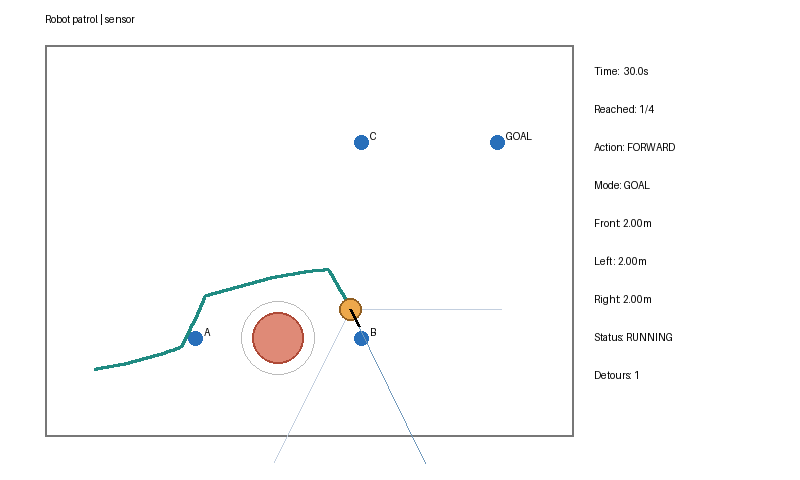

In [8]:
WIDTH, HEIGHT = 800, 480
X0, Y0, X1, Y1 = 45, 45, 573, 436
WORLD_W, WORLD_H = 7.0, 4.4
FONT_PATH = "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"
try:
    FONT = ImageFont.truetype(FONT_PATH, 15)
except OSError:
    FONT = ImageFont.load_default()


def to_pixel(x, y):
    return (int(X0 + x / WORLD_W * (X1-X0)),
            int(Y1 - y / WORLD_H * (Y1-Y0)))


def draw_frame(row, past_rows, mode):
    pic = Image.new("RGB", (WIDTH, HEIGHT), "white")
    d = ImageDraw.Draw(pic)
    d.text((45, 13), f"Robot patrol | {mode}", font=FONT, fill="black")
    d.rectangle([X0,Y0,X1,Y1], outline="#777777", width=2)
    # 障害物の可視化。ここは評価側の正解位置を描く（ロボットには渡さない）。
    ox,oy,oradius = OBSTACLE
    px,py = to_pixel(ox,oy)
    scale = (X1-X0)/WORLD_W
    rr = oradius * scale
    danger=(oradius+ROBOT_RADIUS)*scale
    d.ellipse([px-danger,py-danger,px+danger,py+danger], outline="#bbbbbb",width=1)
    d.ellipse([px-rr,py-rr,px+rr,py+rr],fill="#df8a77",outline="#ae4a37",width=2)

    for i, waypoint in enumerate(ROUTE):
        cx,cy=to_pixel(*waypoint)
        d.ellipse([cx-7,cy-7,cx+7,cy+7],fill="#286fba")
        d.text((cx+9,cy-12),"GOAL" if i==3 else chr(65+i),font=FONT,fill="black")
    if len(past_rows)>1:
        d.line([to_pixel(r['x_m'],r['y_m']) for r in past_rows],fill="#208b82",width=3)

    x,y,theta=row['x_m'],row['y_m'],row['theta_rad']
    rx,ry=to_pixel(x,y)
    for angle,dist,color in [
        (theta+math.pi/3,row['left_sensor_m'],"#c3cfdf"),
        (theta,row['front_sensor_m'],"#729abc"),
        (theta-math.pi/3,row['right_sensor_m'],"#c3cfdf")]:
        ex,ey=to_pixel(x+dist*math.cos(angle),y+dist*math.sin(angle))
        d.line([rx,ry,ex,ey],fill=color,width=1)
    d.ellipse([rx-11,ry-11,rx+11,ry+11],fill="#eda84b",outline="#915f22",width=2)
    hx,hy=to_pixel(x+.23*math.cos(theta),y+.23*math.sin(theta))
    d.line([rx,ry,hx,hy],fill="black",width=3)

    details = [f"Time: {row['time_s']:5.1f}s",f"Reached: {row['checkpoints_reached']}/4",
        f"Action: {row['action']}",f"Mode: {row['phase']}",
        f"Front: {row['front_sensor_m']:.2f}m", f"Left : {row['left_sensor_m']:.2f}m",
        f"Right: {row['right_sensor_m']:.2f}m",f"Status: {row['status']}",
        f"Detours: {row['detour_count']}"]
    for i,s in enumerate(details):
        d.text((594,65+i*38),s,font=FONT,fill="black")
    return pic

from IPython.display import display
display(draw_frame(sensor_rows[360],sensor_rows[:361],"sensor"))

## 9. 動画・静止画の保存



In [9]:
MAKE_BASELINE_VIDEO = True

def save_video(rows, mode):
    filename = Path(f"PAI_obstacle_{mode}.mp4")
    snapshot = Path(f"snapshot_{mode}.png")
    writer = cv2.VideoWriter(str(filename), cv2.VideoWriter_fourcc(*"mp4v"), FPS, (WIDTH,HEIGHT))
    if not writer.isOpened():
        raise RuntimeError("MP4を書き出せません。OpenCVのインストールを確認してください")
    for i,row in enumerate(rows):
        picture=draw_frame(row,rows[:i+1],mode)
        if i==min(FPS*36,len(rows)-1):
            picture.save(snapshot)
        writer.write(cv2.cvtColor(np.asarray(picture),cv2.COLOR_RGB2BGR))
    writer.release()
    if shutil.which("ffmpeg"):
        temp=filename.with_name(filename.stem+"_h264.mp4")
        p=subprocess.run(["ffmpeg","-y","-hide_banner","-loglevel","error", "-i",str(filename),
                          "-c:v","libx264","-preset","veryfast","-crf","25", "-pix_fmt","yuv420p",str(temp)],
                         capture_output=True,text=True)
        if p.returncode==0 and temp.exists() and temp.stat().st_size>0:
            temp.replace(filename)
        elif temp.exists(): temp.unlink()
    print("保存しました:",filename)
    return filename

sensor_video=save_video(sensor_rows,"sensor")
if MAKE_BASELINE_VIDEO:
    baseline_video=save_video(baseline_rows,"baseline")

保存しました: PAI_obstacle_sensor.mp4
保存しました: PAI_obstacle_baseline.mp4
